# Polvorones - Sintesis ASIC (interactivo)

Capsula 6. El sintetizador es el **traductor**: pasa del RTL (el *que*) a un
**netlist de compuertas** (el *con que*), eligiendo del catalogo del PDK las
celdas mas baratas que cumplan. Aqui sintetizamos el `semaforo` a **celdas
estandar SKY130** y vemos cuantas usa (las **polvorones**) y cuanta **area**.

> Corre las celdas en orden. La primera baja el PDK SKY130 (volare, ~1-2 min).

## 1 - Preparar (Yosys + PDK SKY130 + repo)

In [1]:
import os, subprocess, re
!apt-get -qq update && apt-get -qq install -y yosys > /dev/null
!pip -q install volare
import matplotlib.pyplot as plt

# PDK SKY130 (trae el .lib de celdas estandar)
os.environ['PDK_ROOT'] = '/content/pdk'
out = subprocess.run(['volare','ls-remote','--pdk','sky130'], capture_output=True, text=True).stdout
ver = next(iter(re.findall(r'\b[0-9a-f]{7,40}\b', out)), None)
print('Habilitando PDK version:', ver)
!volare enable --pdk sky130 {ver}
LIB = '/content/pdk/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
print('¿lib de celdas existe?', os.path.exists(LIB))

# el repo (para el RTL)
REPO = 'galletas-y-postres-chips'
if not os.path.isdir(REPO):
    !git clone --depth 1 https://github.com/Misterio12947/galletas-y-postres-chips.git
RTL = f'{REPO}/common/rtl/semaphore/rtl/semaphore.v'
assert os.path.exists(RTL)
print('Todo listo.')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 7.2 MB/s eta 0:00:00
Habilitando PDK version: c6d73a35f524070e85faff4a6a9eef49553ebc2b
no oauth token found for github.com
Version c6d73a35f524070e85faff4a6a9eef49553ebc2b not found locally, attempting 
to download…
⠏ Unpacking common.tar.zst…
⠙ Unpacking sky130_fd_io.tar.zst…
⠧ Unpacking sky130_fd_pr.tar.zst…
⠸ Unpacking sky130_fd_sc_hd.tar.zst…
⠴ Unpacking sky130_fd_sc_hvl.tar.zst…
⠋ Unpacking sky130_ml_xx_hd.tar.zst…
⠴ Unpacking sky130_sram_macros.tar.zst…
⠋ Enabling version c6d73a35f524070e85faff4a6a9eef49553ebc2b…
Version c6d73a35f524070e85faff4a6a9eef49553ebc2b enabled for the sky130 PDK.
¿lib de celdas existe? True
Cloning into 'galletas-y-postres-chips'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (70/70), do

## 2 - Sintetizar a celdas SKY130

Yosys lee el RTL, lo sintetiza y lo **mapea a celdas reales** del PDK
(`dfflibmap` para los flip-flops, `abc` para la logica). El `stat -liberty`
reporta cuantas celdas y cuanta area.

In [2]:
def sintetizar(cw=8, mostrar_texto=False):
    cmd = (f'read_verilog {RTL}; chparam -set CW {cw} semaforo; '
           f'synth -top semaforo -flatten; '
           f'dfflibmap -liberty {LIB}; abc -liberty {LIB}; opt_clean; '
           f'stat -liberty {LIB}')
    r = subprocess.run(['yosys', '-p', cmd], capture_output=True, text=True)
    out = r.stdout + r.stderr
    celdas = {}
    for nombre, n in re.findall(r'(sky130_fd_sc_hd__\w+)\s+(\d+)', out):
        celdas[nombre] = celdas.get(nombre, 0) + int(n)
    total = sum(celdas.values())
    m = re.search(r'Chip area for.*:\s*([\d.]+)', out)
    area = float(m.group(1)) if m else 0.0
    if mostrar_texto:
        if celdas:
            for k, v in sorted(celdas.items(), key=lambda x: -x[1]):
                print(f'{v:4}  {k}')
        else:
            print('(no se encontraron celdas; ultimas lineas de Yosys:)')
            print('\n'.join(out.splitlines()[-15:]))
    return celdas, total, area

celdas, total, area = sintetizar(cw=8, mostrar_texto=True)
print(f'\n--> {total} celdas estandar   |   area ~ {area:.1f} um^2')

  10  sky130_fd_sc_hd__dfrtp_1
   6  sky130_fd_sc_hd__nor2_1
   3  sky130_fd_sc_hd__mux2_1
   3  sky130_fd_sc_hd__xnor2_1
   2  sky130_fd_sc_hd__and4_1
   2  sky130_fd_sc_hd__nand4_1
   1  sky130_fd_sc_hd__a21o_1
   1  sky130_fd_sc_hd__a21oi_1
   1  sky130_fd_sc_hd__a31oi_1
   1  sky130_fd_sc_hd__and3_1
   1  sky130_fd_sc_hd__dfstp_2
   1  sky130_fd_sc_hd__lpflow_isobufsrc_1
   1  sky130_fd_sc_hd__nand2_1
   1  sky130_fd_sc_hd__nor3_1
   1  sky130_fd_sc_hd__nor4_1
   1  sky130_fd_sc_hd__o21ai_0
   1  sky130_fd_sc_hd__xor2_1

--> 37 celdas estandar   |   area ~ 449.2 um^2


## 3 - Las polvorones (que celdas uso)

Cada barra es un **tipo de celda estandar** y cuantas veces se repite -- las
polvorones salidas del mismo molde. Inversores, NANDs, flip-flops...

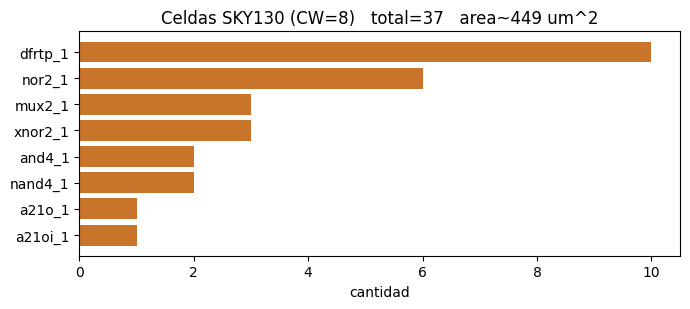

In [3]:
def grafica(cw=8):
    celdas, total, area = sintetizar(cw)
    top = sorted(celdas.items(), key=lambda x: -x[1])[:8]
    nombres = [k.replace('sky130_fd_sc_hd__', '') for k, _ in top]
    valores = [v for _, v in top]
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.barh(nombres[::-1], valores[::-1], color='#C8742B')
    ax.set_xlabel('cantidad')
    ax.set_title(f'Celdas SKY130 (CW={cw})   total={total}   area~{area:.0f} um^2')
    plt.tight_layout(); plt.show()

grafica(8)

## 4 - Juega: mas logica = mas celdas y mas area

Sube `CW` (el ancho del contador) y mira crecer el **numero de celdas** y el
**area**. Eso es la parte 'A' del PPA: cuanto silicio ocupa.

In [4]:
from ipywidgets import interact, IntSlider
interact(grafica, cw=IntSlider(8, 2, 24, description='CW'));

interactive(children=(IntSlider(value=8, description='CW', max=24, min=2), Output()), _dom_classes=('widget-in…

## 5 - ¿Y como sabemos que no se rompio? (equivalence checking)

La sintesis **reorganizo y optimizo** todo... pero el netlist debe hacer
*exactamente* lo mismo que el RTL. Eso se **demuestra** (no se simula) con
**equivalence checking**: open source con `eqy`, en Synopsys con `Formality`.
Es el mismo motor formal de la Gelatina, ahora comparando **RTL vs netlist**.

## Lo que sigue

Ya tenemos el netlist de compuertas; ahora hay que **acomodarlas** en el chip
y **conectarlas**.

🍪 Polvorones &nbsp;->&nbsp; 🍰 Pastel Tres Leches (PnR)